DATA CLEANING

1.Data Import & Load

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv('Kelantan_Crime_Statistic.csv',
    encoding='latin1'
)

df.head()



,state,district,category,type,date,crimes
0,Kelantan,All,assault,all,1/1/2016,543
1,Kelantan,All,assault,all,1/1/2017,600
2,Kelantan,All,assault,all,1/1/2018,511
3,Kelantan,All,assault,all,1/1/2019,470
4,Kelantan,All,assault,all,1/1/2020,504


2. Check Duplicate Rows

In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
1227,False
1228,False
1229,False
1230,False


3. Identify Column Data Types

In [ ]:
cat_col = [col for col in df.columns if df[col].dtype == 'object']
num_col = [col for col in df.columns if df[col].dtype != 'object']

print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)

Categorical columns: ['state', 'district', 'category', 'type', 'date']
Numerical columns: ['crimes']


4. Count Unique Values in Categorical COlumns

In [ ]:
df[cat_col].nunique()

,0
state,1
district,11
category,2
type,13
date,8


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
1227,False
1228,False
1229,False
1230,False


5. Calculate Missing Values

In [ ]:
round((df.isnull().sum() / df.shape[0]) * 100, 2)

,0
state,0.0
district,0.0
category,0.0
type,0.0
date,0.0
crimes,0.0


6. Dropping Irrelevant Columns
- Dropping 'state' column

In [ ]:
df1 = df.drop(columns=['state'])
df1['date'] = pd.to_datetime(df1['date'])
df1['year'] = df1['date'].dt.year
df1['crimes'] = df1['crimes'].fillna(df1['crimes'].mean())

7. Detect Outliers using Box Plot

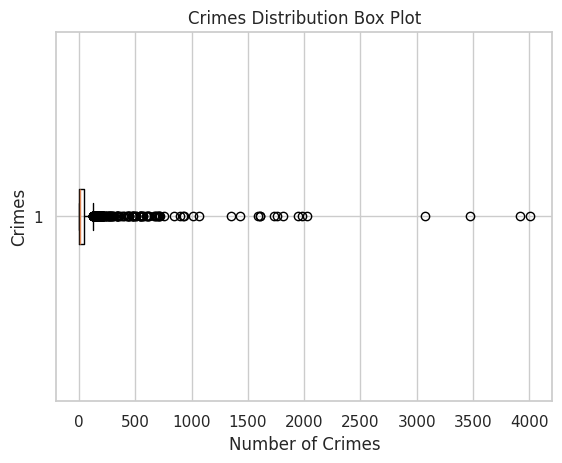

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot(df1['crimes'], vert=False)

plt.ylabel('Crimes')
plt.xlabel('Number of Crimes')
plt.title('Crimes Distribution Box Plot')

plt.show()

8. Calculate Outlier Boundaries and Remove the Outlier

In [ ]:
mean = df1['crimes'].mean()
std = df1['crimes'].std()

lower_bound = mean - 2 * std
upper_bound = mean + 2 * std

df2 = df1[(df1['crimes'] >= lower_bound) & (df1['crimes'] <= upper_bound)]

9. Impute Missing Data

In [ ]:
df3 = df2.fillna(df2['crimes'].mean())
df3.isnull().sum()

,0
district,0
category,0
type,0
date,0
crimes,0
year,0


10. Recalculate Outlier Bounds and Remove Outliers from the Updated Data

In [ ]:
mean = df3['crimes'].mean()
std = df3['crimes'].std()

lower_bound = mean - 2 * std
upper_bound = mean + 2 * std

print('Lower Bound :', lower_bound)
print('Upper Bound :', upper_bound)

df4 = df3[(df3['crimes'] >= lower_bound) & (df3['crimes'] <= upper_bound)]

Lower Bound : -141.03762345641383
Upper Bound : 234.3321326078281


11. Data Validation and Verification

In [ ]:
X = df3[['year', 'category', 'district']]
Y = df3['crimes']

12. Data Formatting

In [ ]:
X = df3[['year', 'category', 'district']]
X = pd.get_dummies(X)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

a. Min-Max Scaling

In [ ]:
X = df3[['year']]

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[0.        ]
 [0.14285714]
 [0.28571429]
 [0.42857143]
 [0.57142857]]


b. Standardization

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

print(X_standardized[:5])

[[-1.53764629]
 [-1.10112034]
 [-0.6645944 ]
 [-0.22806846]
 [ 0.20845748]]


DATA PREPROCESSING

1. Dataset Import and Load

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('Kelantan_Crime_Statistic.csv')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df.head()

,state,district,category,type,date,crimes,year
0,Kelantan,All,assault,all,2016-01-01,543,2016
1,Kelantan,All,assault,all,2017-01-01,600,2017
2,Kelantan,All,assault,all,2018-01-01,511,2018
3,Kelantan,All,assault,all,2019-01-01,470,2019
4,Kelantan,All,assault,all,2020-01-01,504,2020


2. Inspect Data Structure and Check Missing Values

In [ ]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1232 entries, 0 to 1231
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   state     1232 non-null   object        
 1   district  1232 non-null   object        
 2   category  1232 non-null   object        
 3   type      1232 non-null   object        
 4   date      1232 non-null   datetime64[ns]
 5   crimes    1232 non-null   int64         
 6   year      1232 non-null   int32         
dtypes: datetime64[ns](1), int32(1), int64(1), object(4)
memory usage: 62.7+ KB
state       0
district    0
category    0
type        0
date        0
crimes      0
year        0
dtype: int64


3. Statistical Summary and Visualizing Outliers

Box Plot of 'crimes' Grouped by 'category'

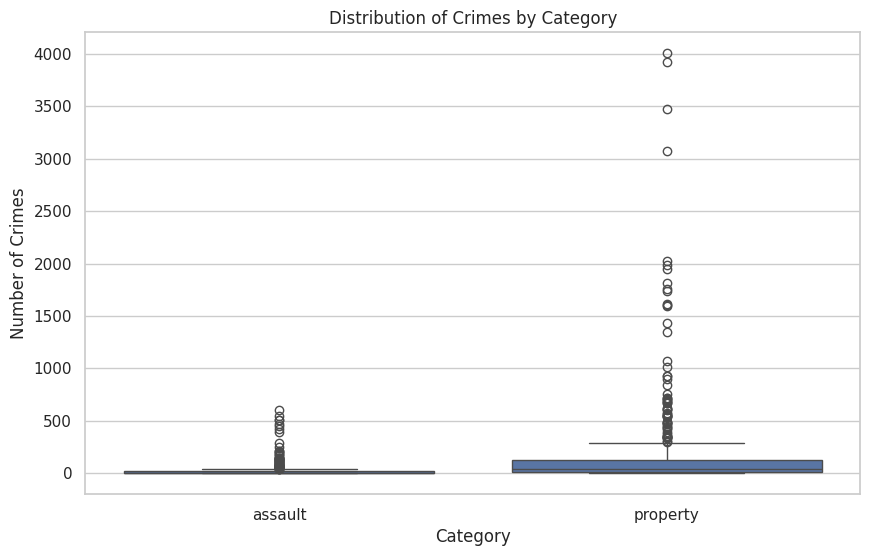

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='category', y='crimes', data=df)
plt.title('Distribution of Crimes by Category')
plt.xlabel('Category')
plt.ylabel('Number of Crimes')
plt.show()

Box Plot of 'crimes' Grouped by 'district'

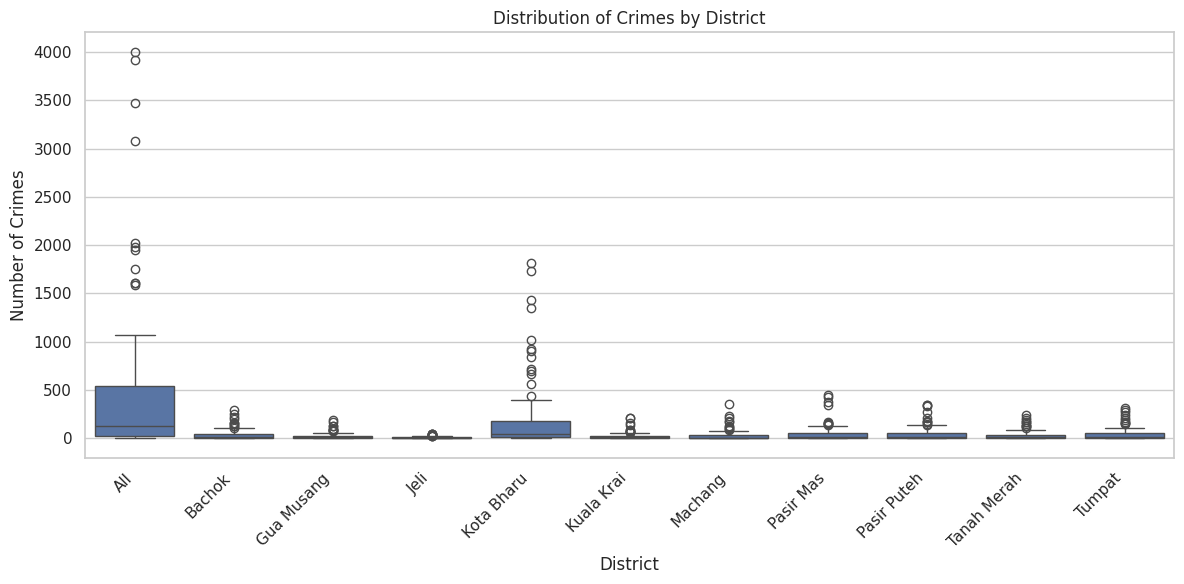

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='district', y='crimes', data=df)
plt.title('Distribution of Crimes by District')
plt.xlabel('District')
plt.ylabel('Number of Crimes')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout()
plt.show()

Average Number of Crimes per District

In [ ]:
average_crimes_per_district = df.groupby('district')['crimes'].mean().sort_values(ascending=False)
display(average_crimes_per_district)

,crimes
district,
All,452.642857
Kota Bharu,185.339286
Pasir Mas,44.607143
Pasir Puteh,43.464286
Tumpat,38.857143
Bachok,34.892857
Tanah Merah,29.821429
Machang,27.303571
Gua Musang,21.089286


5. Correlation Analysis using Heatmap of Crimes by District and Category

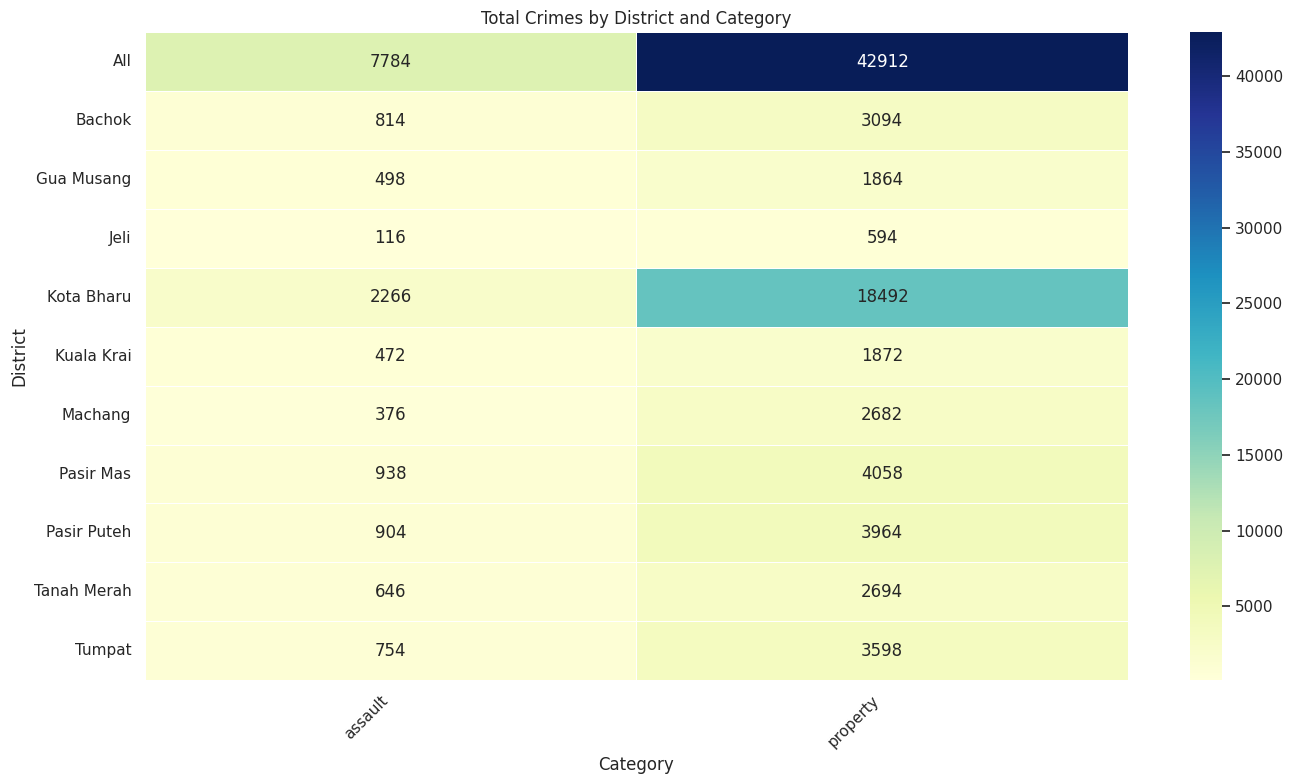

In [ ]:
crime_pivot = df.pivot_table(index='district', columns='category', values='crimes', aggfunc='sum')

plt.figure(figsize=(14, 8))
sns.heatmap(crime_pivot, annot=True, fmt='g', cmap='YlGnBu', linewidths=.5)
plt.title('Total Crimes by District and Category')
plt.xlabel('Category')
plt.ylabel('District')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns
correlation_matrix_all = df[numerical_cols].corr()
display(correlation_matrix_all)

,crimes,year
crimes,1.000000,-0.090261
year,-0.090261,1.000000


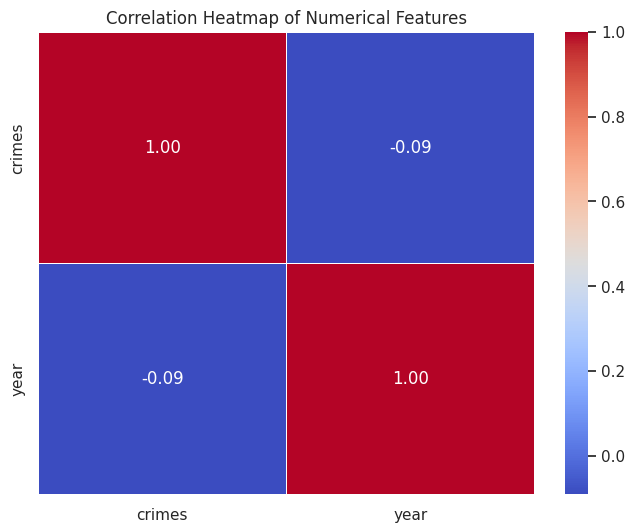

In [ ]:
numerical_df = df[['crimes', 'year']]
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

6. Visualize Target Variable Distribution

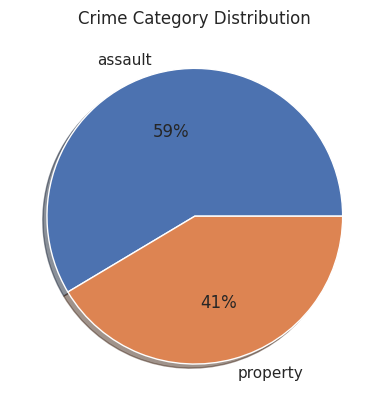

In [ ]:
plt.pie(df3['category'].value_counts(),
        labels=df3['category'].value_counts().index,
        autopct='%.f%%',
        shadow=True)

plt.title('Crime Category Distribution')
plt.show()

7. Separate Features & Target Variable

In [ ]:
X = df3[['year']]
y = df3['crimes']

8. Feature Scaling: Normalization and Standardization

In [ ]:
# Normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)

print(X_normalized[:5])

[[0.        ]
 [0.14285714]
 [0.28571429]
 [0.42857143]
 [0.57142857]]


In [ ]:
# Standardization
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

print(X_standardized[:5])

[[-1.53764629]
 [-1.10112034]
 [-0.6645944 ]
 [-0.22806846]
 [ 0.20845748]]


EDA-EXPLORATORY DATA ANALYSIS

1. Importing Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
wr.filterwarnings('ignore')

2. Reading Dataset

In [ ]:
df = pd.read_csv("Kelantan_Crime_Statistic.csv")
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
print(df.head())

      state district category type       date  crimes  year
0  Kelantan      All  assault  all 2016-01-01     543  2016
1  Kelantan      All  assault  all 2017-01-01     600  2017
2  Kelantan      All  assault  all 2018-01-01     511  2018
3  Kelantan      All  assault  all 2019-01-01     470  2019
4  Kelantan      All  assault  all 2020-01-01     504  2020


3. Data Analysing

In [ ]:
df.shape

(1232, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1232 entries, 0 to 1231
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   state     1232 non-null   object        
 1   district  1232 non-null   object        
 2   category  1232 non-null   object        
 3   type      1232 non-null   object        
 4   date      1232 non-null   datetime64[ns]
 5   crimes    1232 non-null   int64         
 6   year      1232 non-null   int32         
dtypes: datetime64[ns](1), int32(1), int64(1), object(4)
memory usage: 62.7+ KB


In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,1232,2019-07-02 18:00:00,2016-01-01 00:00:00,2017-10-01 18:00:00,2019-07-02 12:00:00,2021-04-02 06:00:00,2023-01-01 00:00:00,NaN
crimes,1232.0,82.298701,0.0,1.0,12.0,49.25,4005.0,285.615914
year,1232.0,2019.5,2016.0,2017.75,2019.5,2021.25,2023.0,2.292218


In [ ]:
df.columns.tolist()

['state', 'district', 'category', 'type', 'date', 'crimes', 'year']

4. Check Missing Values

In [ ]:
df.isnull().sum()

,0
state,0
district,0
category,0
type,0
date,0
crimes,0
year,0


5. Checking Duplicate Rows

In [ ]:
df.duplicated().sum()

np.int64(0)

6. Univariate Analysis

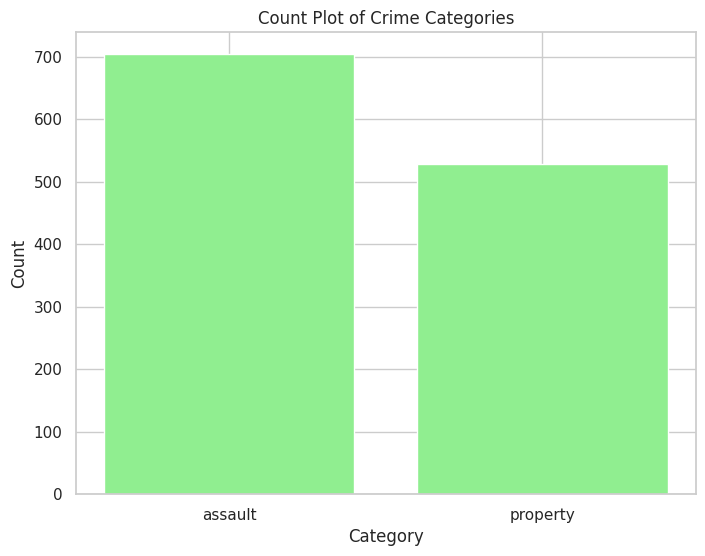

In [ ]:
category_counts = df['category'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(category_counts.index, category_counts, color='lightgreen')
plt.title('Count Plot of Crime Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

Histograms of Numerical Features with KDE and Skewness

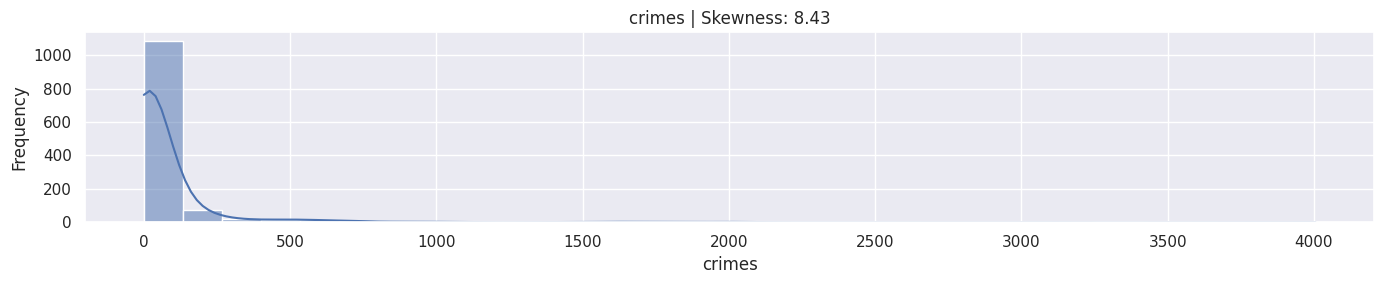

In [ ]:
sns.set_style("darkgrid")

numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 1, idx)
    sns.histplot(df[feature], kde=True, bins=30)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Swarm Plot of Crimes by Category

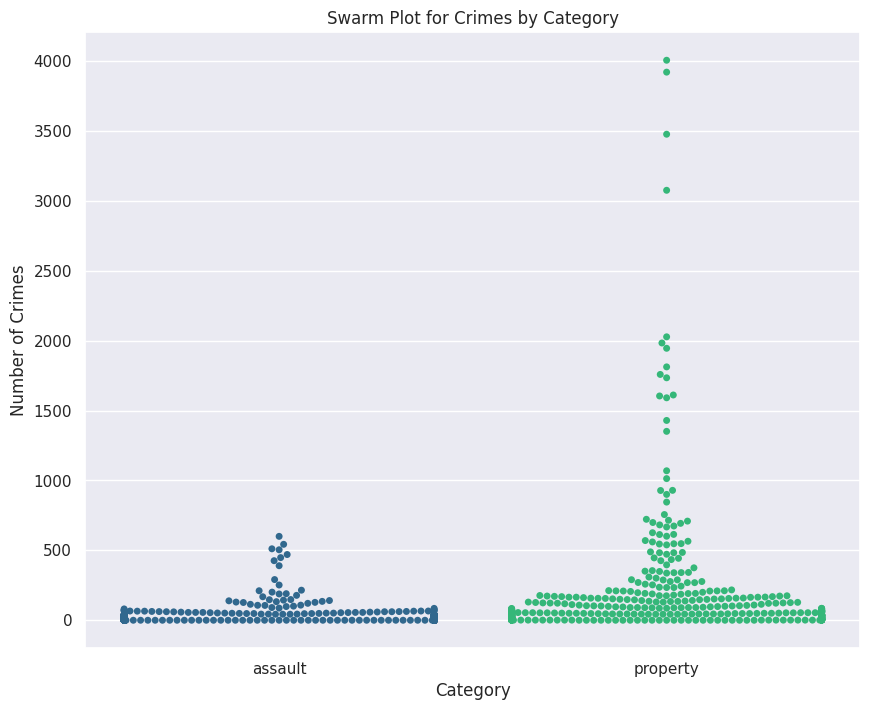

In [ ]:
plt.figure(figsize=(10, 8))
sns.swarmplot(x="category", y="crimes", data=df, palette='viridis')
plt.title('Swarm Plot for Crimes by Category')
plt.xlabel('Category')
plt.ylabel('Number of Crimes')
plt.show()

Histogram of 'Assault' Crimes by District and Year

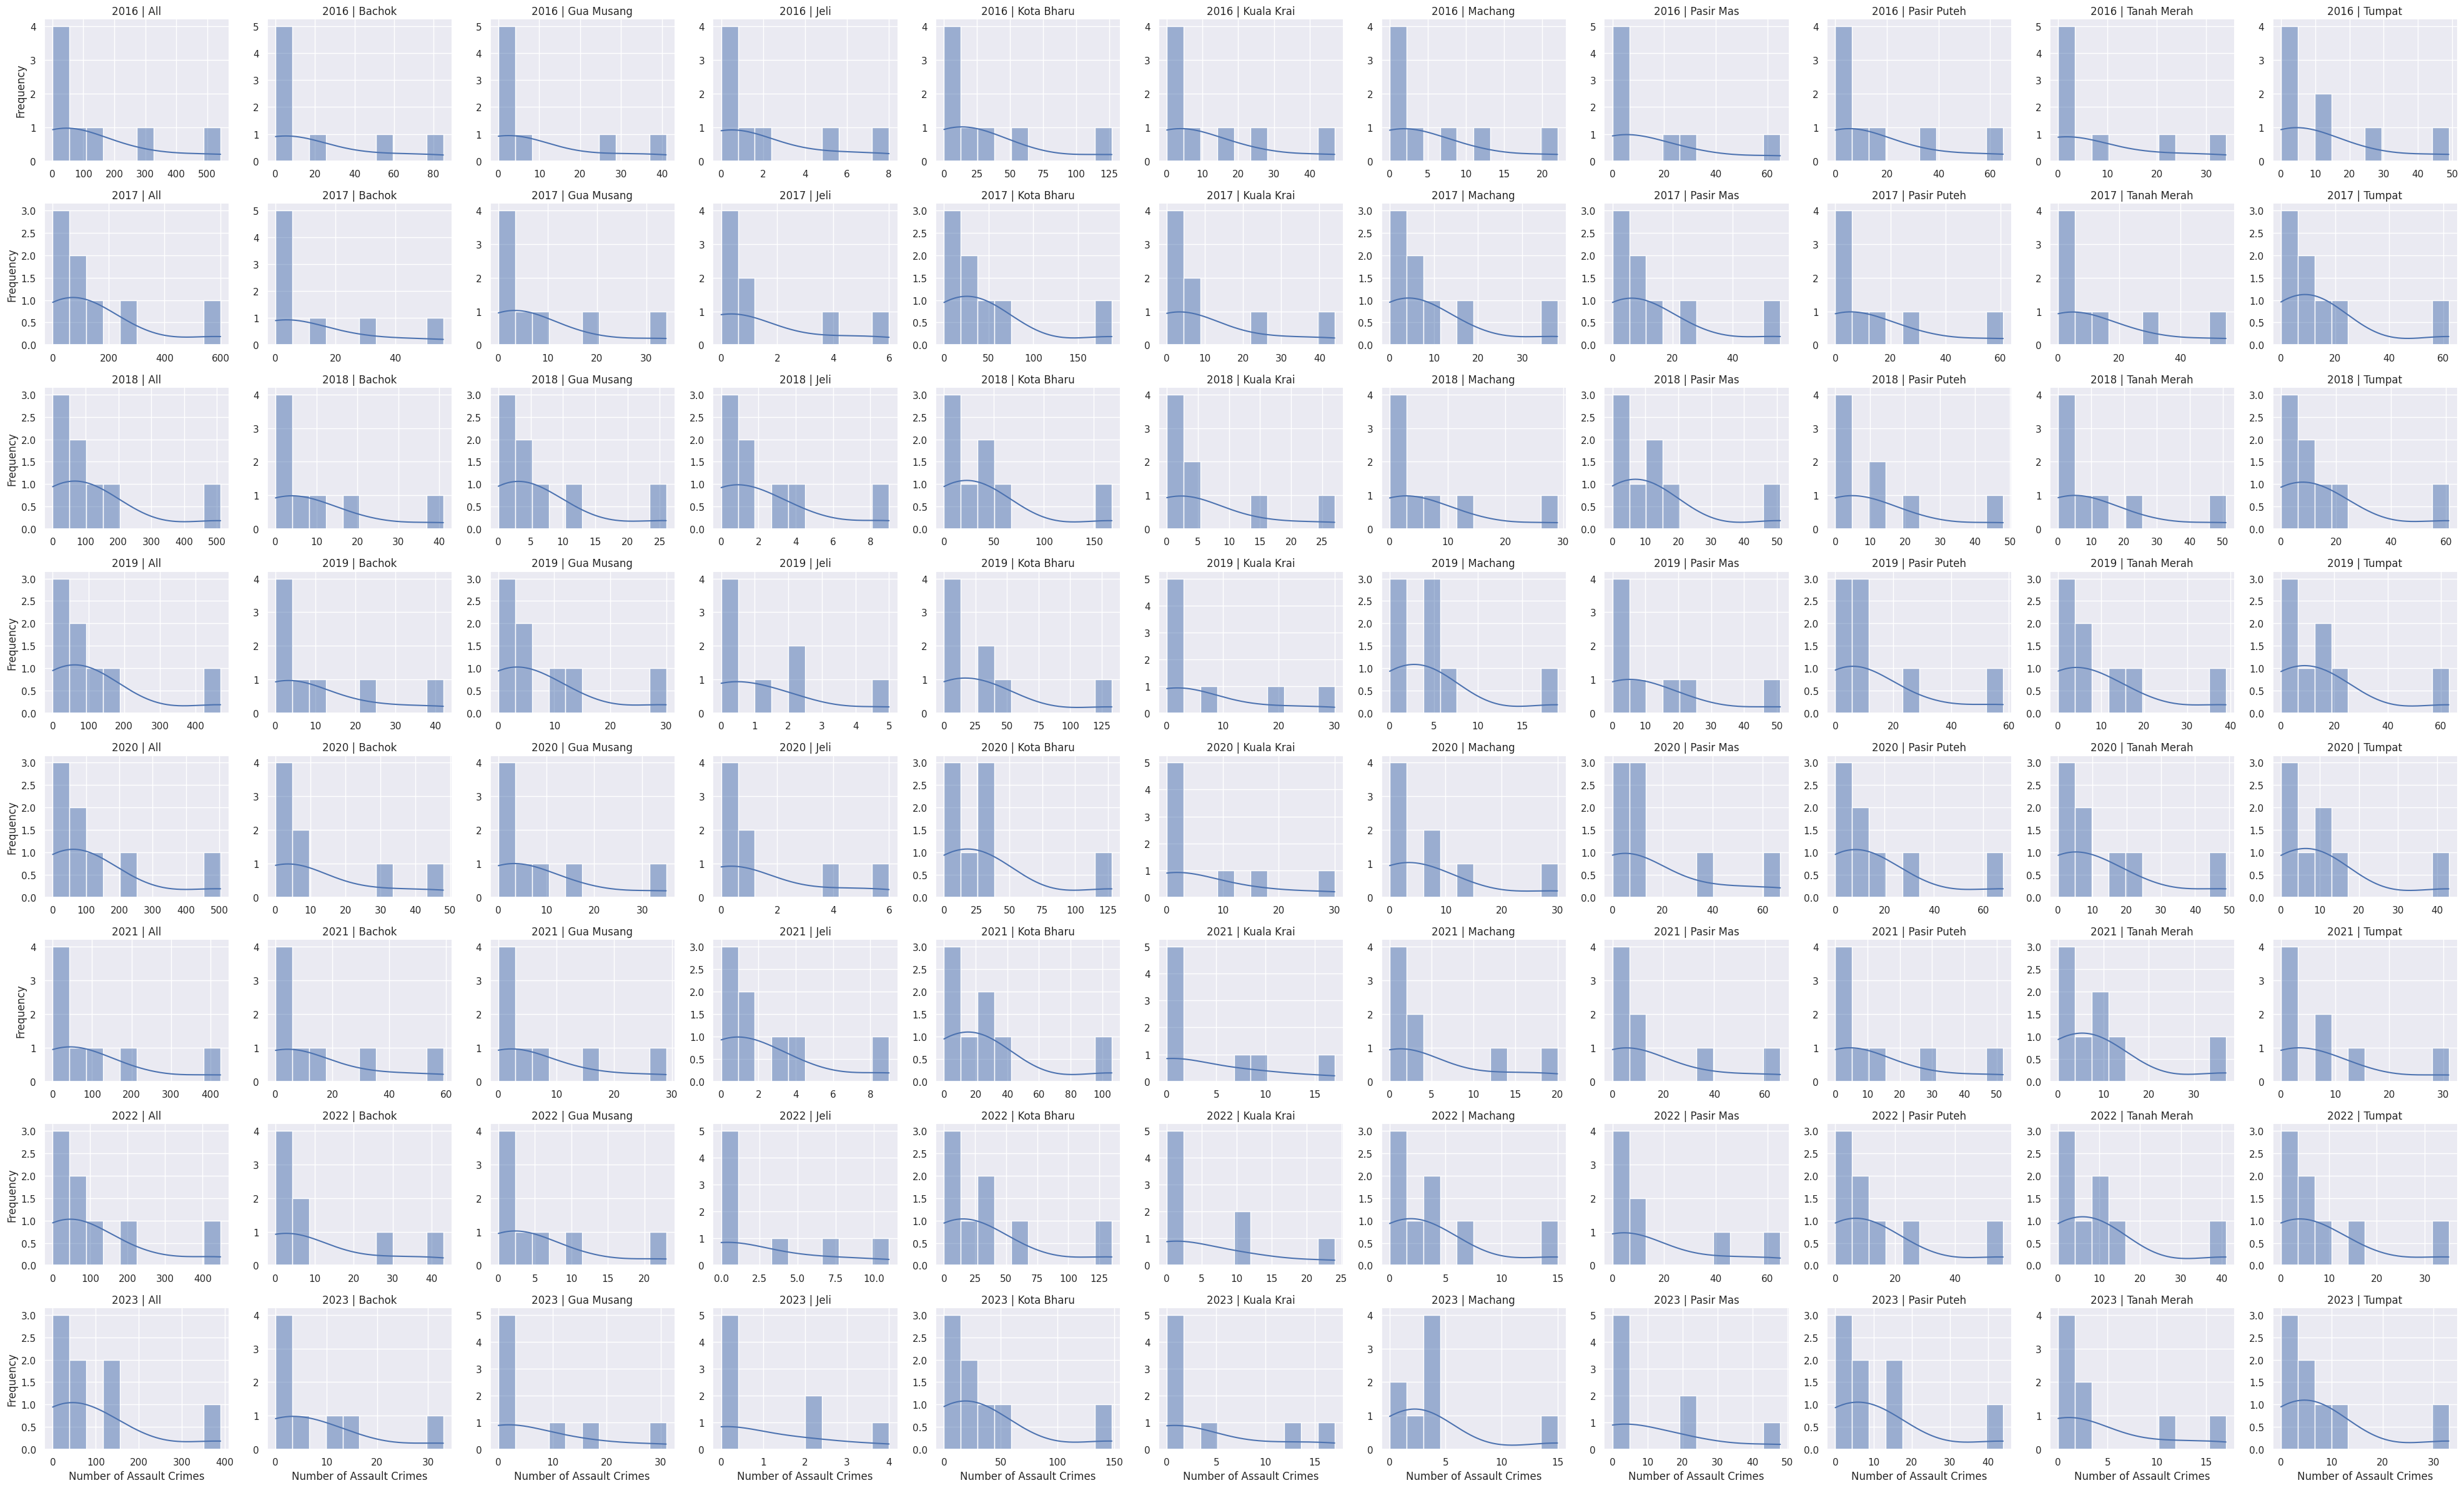

In [ ]:
assault_df = df[df['category'] == 'assault']

g = sns.FacetGrid(assault_df, col='district', row='year', height=3, aspect=1.2, sharex=False, sharey=False)
g.map(sns.histplot, 'crimes', bins=10, kde=True)

g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.set_axis_labels("Number of Assault Crimes", "Frequency")
g.tight_layout()
plt.show()

Heatmap of Total Crimes by District and Year

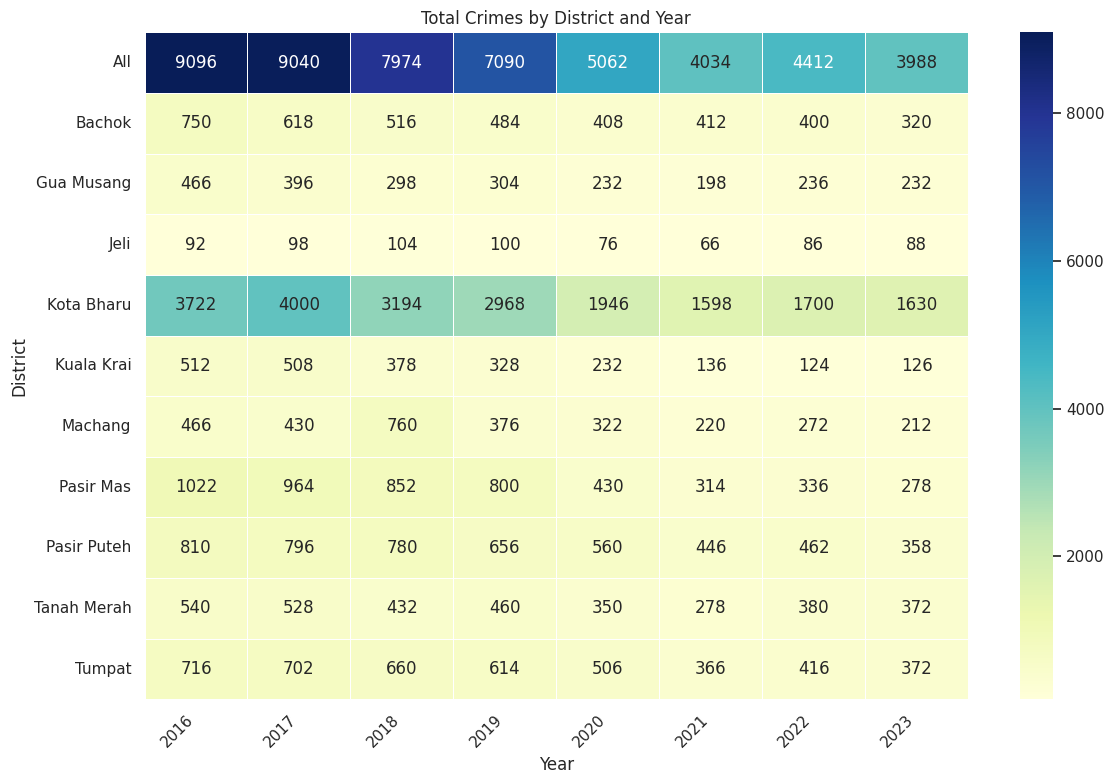

In [ ]:
crime_by_district_year = df.pivot_table(index='district', columns='year', values='crimes', aggfunc='sum')

plt.figure(figsize=(12, 8))
sns.heatmap(crime_by_district_year, annot=True, fmt='g', cmap='YlGnBu', linewidths=.5)
plt.title('Total Crimes by District and Year')
plt.xlabel('Year')
plt.ylabel('District')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

7. Bivariate Analysis

Pair Plot of Numerical Features

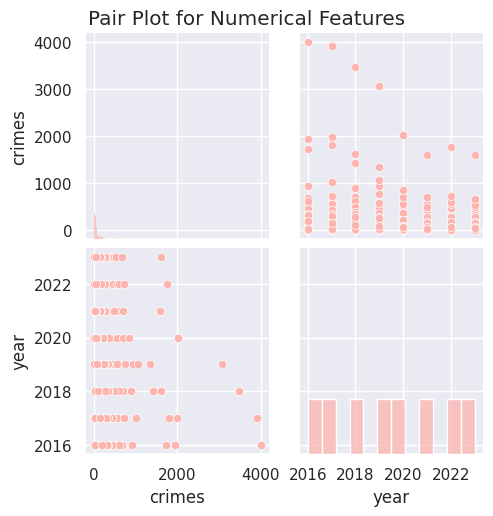

In [ ]:
sns.set_palette("Pastel1")

# Select only numerical columns for pairplot
numerical_df_for_pairplot = df[['crimes', 'year']]

sns.pairplot(numerical_df_for_pairplot)

plt.suptitle('Pair Plot for Numerical Features', y=1.02)
plt.show()

Violin Plot of Crimes by Category

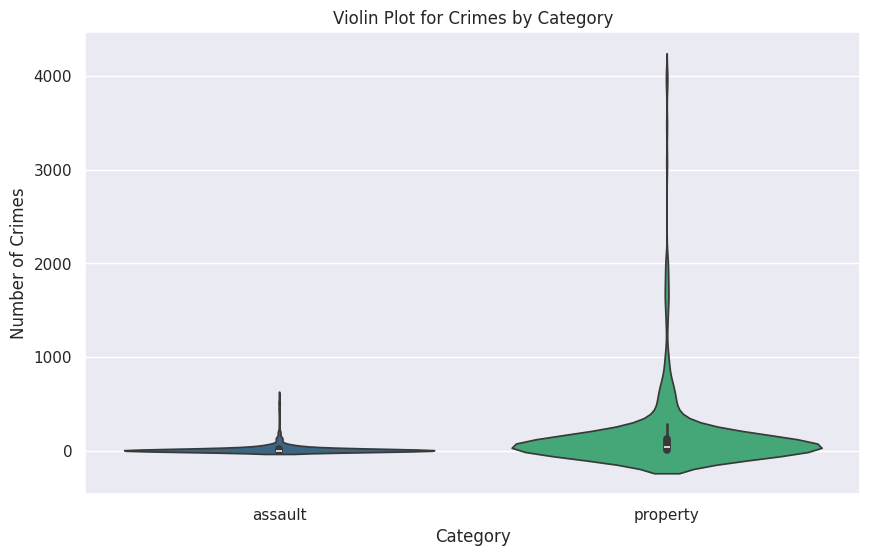

In [ ]:
plt.figure(figsize=(10, 6))
sns.violinplot(x="category", y="crimes", data=df, palette='viridis')
plt.title('Violin Plot for Crimes by Category')
plt.xlabel('Category')
plt.ylabel('Number of Crimes')
plt.show()

Box Plots of Crimes by District for Each Year (2016-2023)

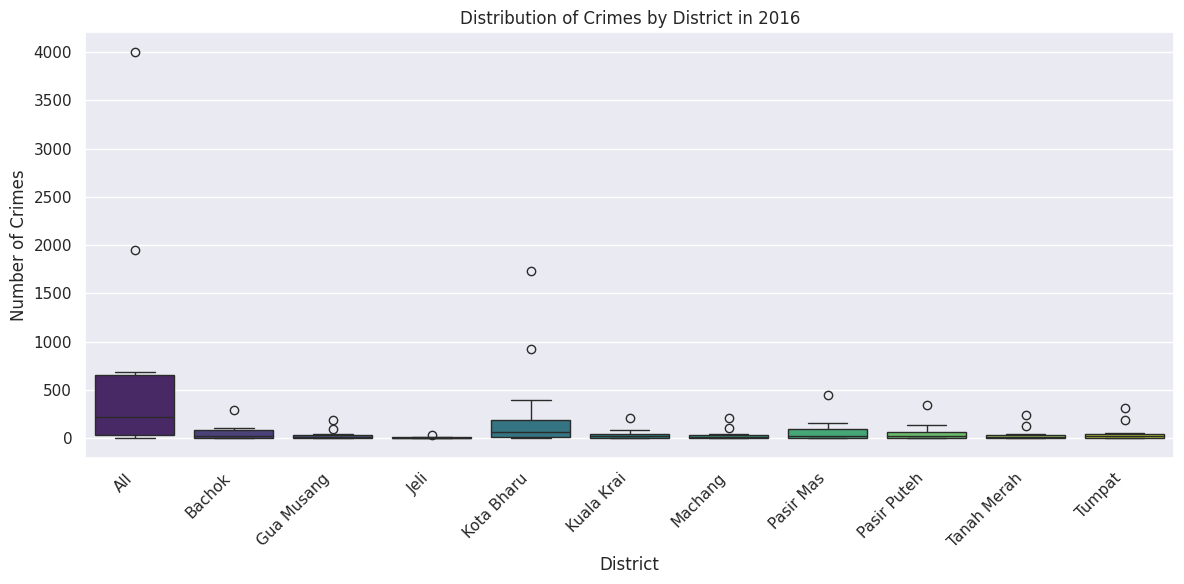

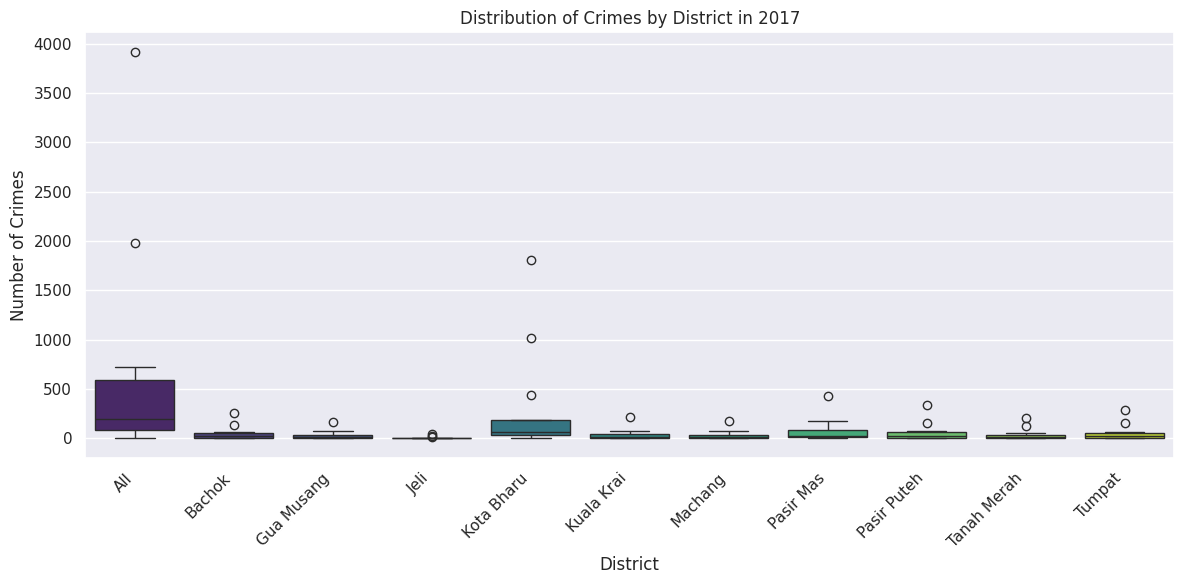

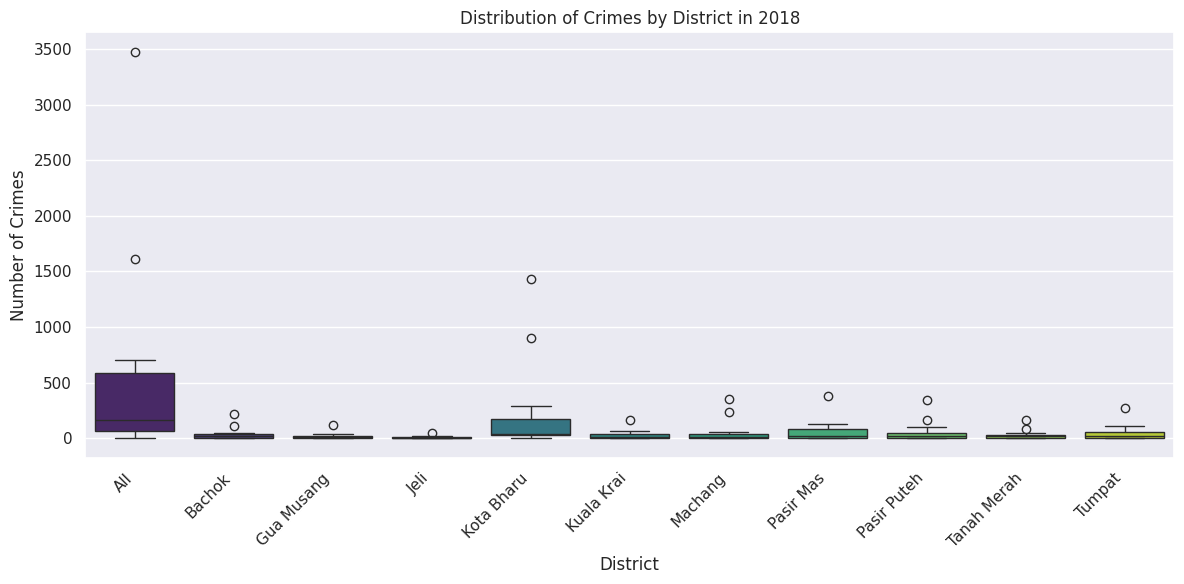

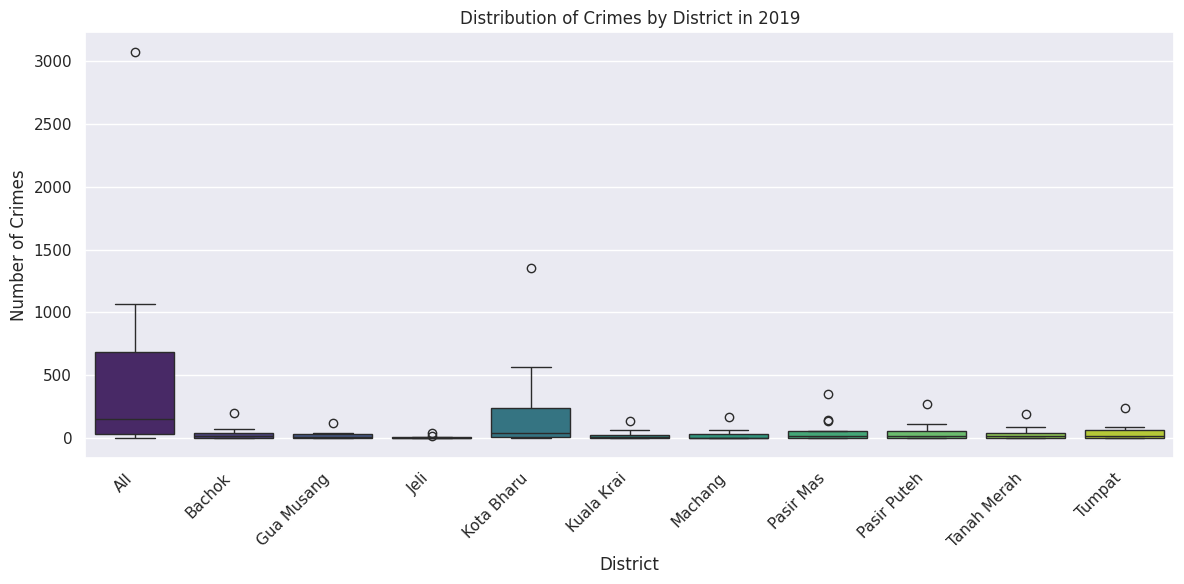

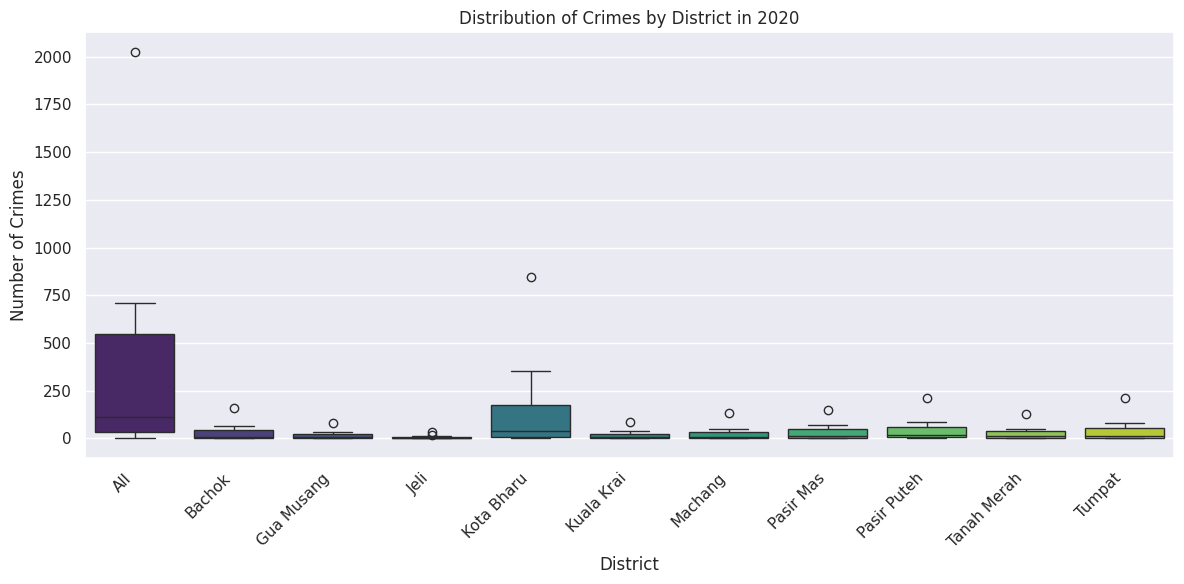

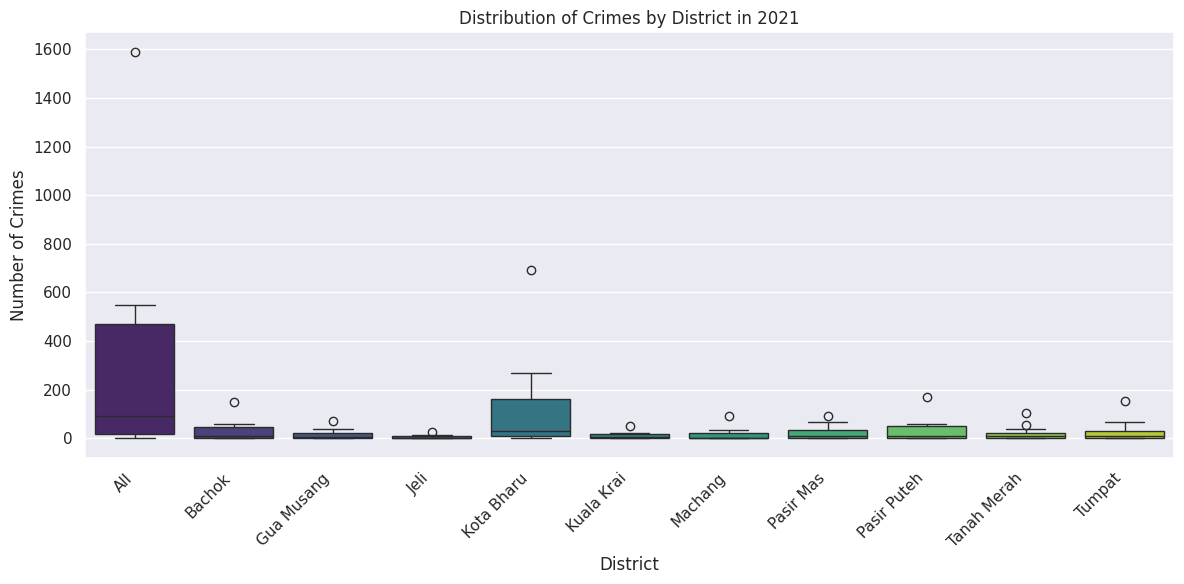

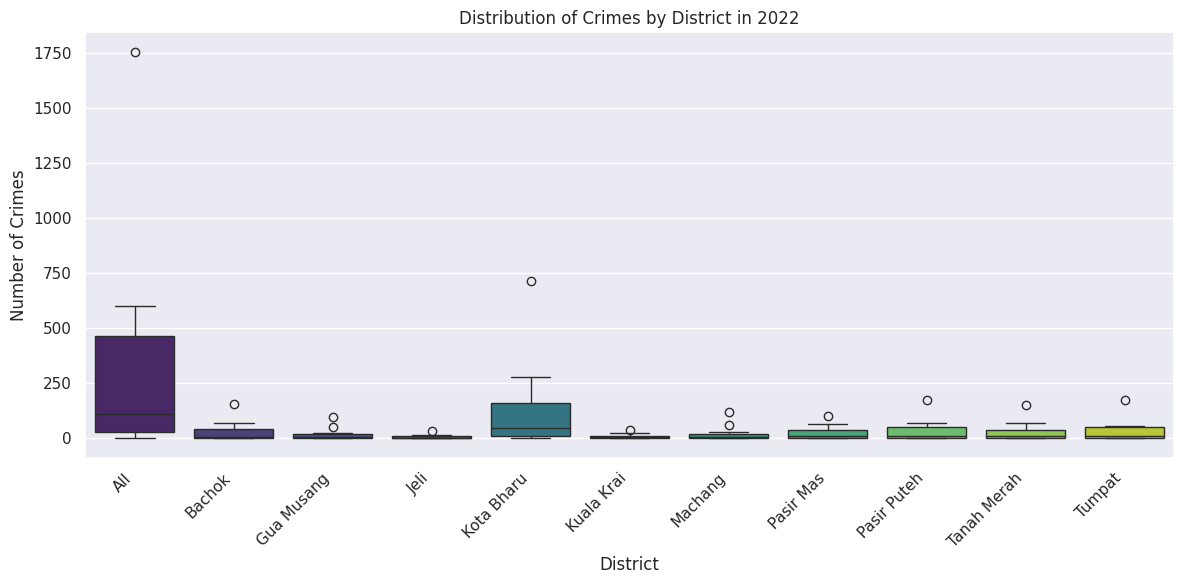

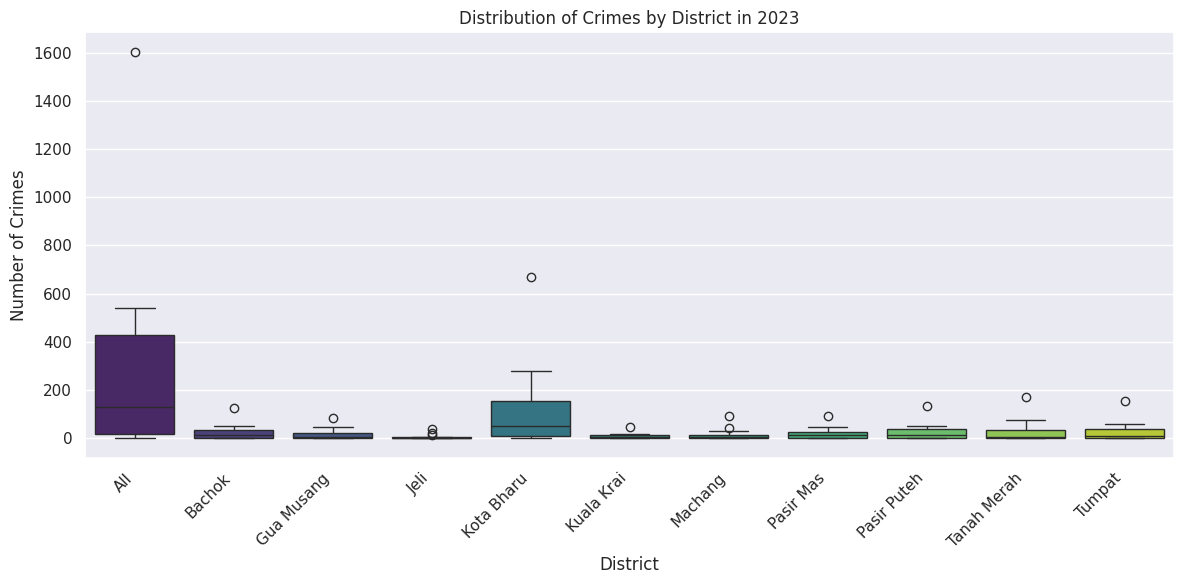

In [ ]:
years = range(2016, 2024)

for year in years:
    plt.figure(figsize=(12, 6))
    df_year = df[df['year'] == year]
    sns.boxplot(x='district', y='crimes', data=df_year, palette='viridis')
    plt.title(f'Distribution of Crimes by District in {year}')
    plt.xlabel('District')
    plt.ylabel('Number of Crimes')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

8. Multivariate Analysis

Correlation Heatmap

Correlation Heatmap of Numerical Features

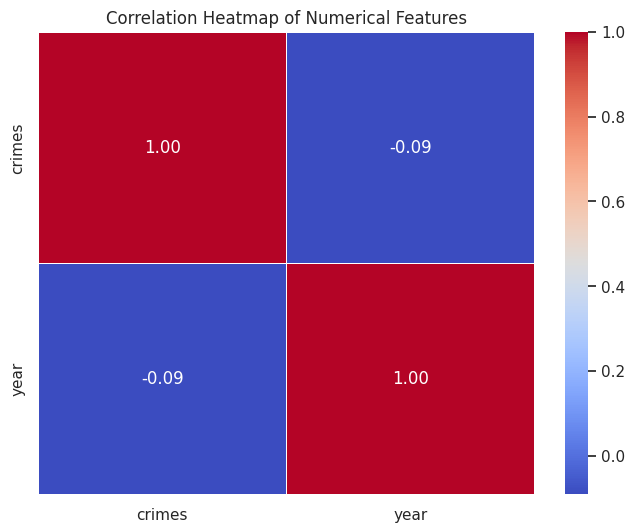

In [ ]:
plt.figure(figsize=(8, 6))
# Calculate correlation matrix for numerical columns in df
correlation_matrix_df = df.select_dtypes(include=['number']).corr()

sns.heatmap(correlation_matrix_df, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## K-Means Clustering Implementation
### 1. Data Preparation & Feature Scaling
We load the dataset, pivot it to group crimes by district, and standardize the features so the K-Means algorithm weights all crime categories equally.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Pivot the data to get total crimes per category for each district
clustering_df = df.pivot_table(index='district', columns='category', values='crimes', aggfunc='sum').fillna(0)

# Scale the data (Standardization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clustering_df)

print("Scaled Features for Clustering (First 5 districts):")
print(X_scaled[:5])

Scaled Features for Clustering (First 5 districts):
[[ 3.05953751  2.92005296]
 [-0.28885151 -0.39157538]
 [-0.44065795 -0.4938734 ]
 [-0.62417081 -0.5994982 ]
 [ 0.40868951  0.88906286]]


### 2. Finding the optimal $K$ using the Elbow Method
To find the optimum number of clusters, we calculate the Within-Cluster Sum of Squares (WCSS) for different values of $K$.

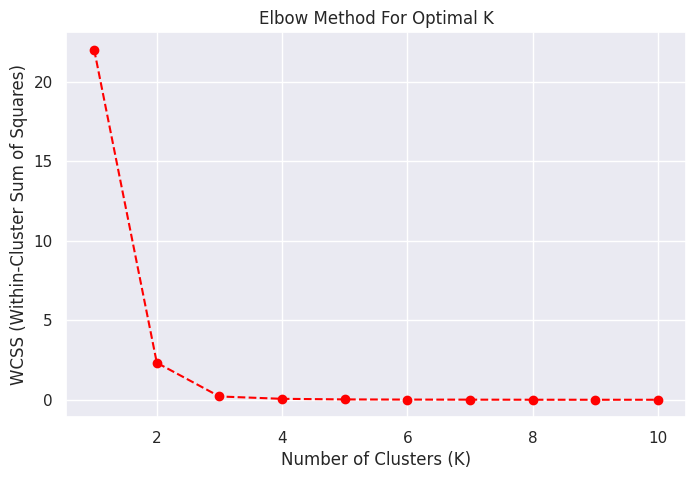

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

wcss = []
k_range = range(1, 11) # Testing K from 1 to 10

for k in k_range:
    # Using k-means++ initialization as recommended in standard implementations
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', color='red', linestyle='dashed')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

### 3. Training the K-Means Model
Assuming the elbow graph shows a distinct bend at $K=3$, we will train the model with 3 clusters and assign the labels to our districts.

In [ ]:
# Set K based on the Elbow method observation
optimal_k = 3

# Train the K-Means model
kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_predictions = kmeans_model.fit_predict(X_scaled)

# Add the cluster labels back to our dataframe
clustering_df['Cluster'] = cluster_predictions

print("Districts with their assigned Clusters:")
display(clustering_df)

Districts with their assigned Clusters:


category,assault,property,Cluster
district,,,
All,7784,42912,2
Bachok,814,3094,1
Gua Musang,498,1864,1
Jeli,116,594,1
Kota Bharu,2266,18492,0
Kuala Krai,472,1872,1
Machang,376,2682,1
Pasir Mas,938,4058,1
Pasir Puteh,904,3964,1


### 4. Visualizing the Clusters and Centroids
We will visualize the clusters using two main crime categories and plot the cluster centroids.

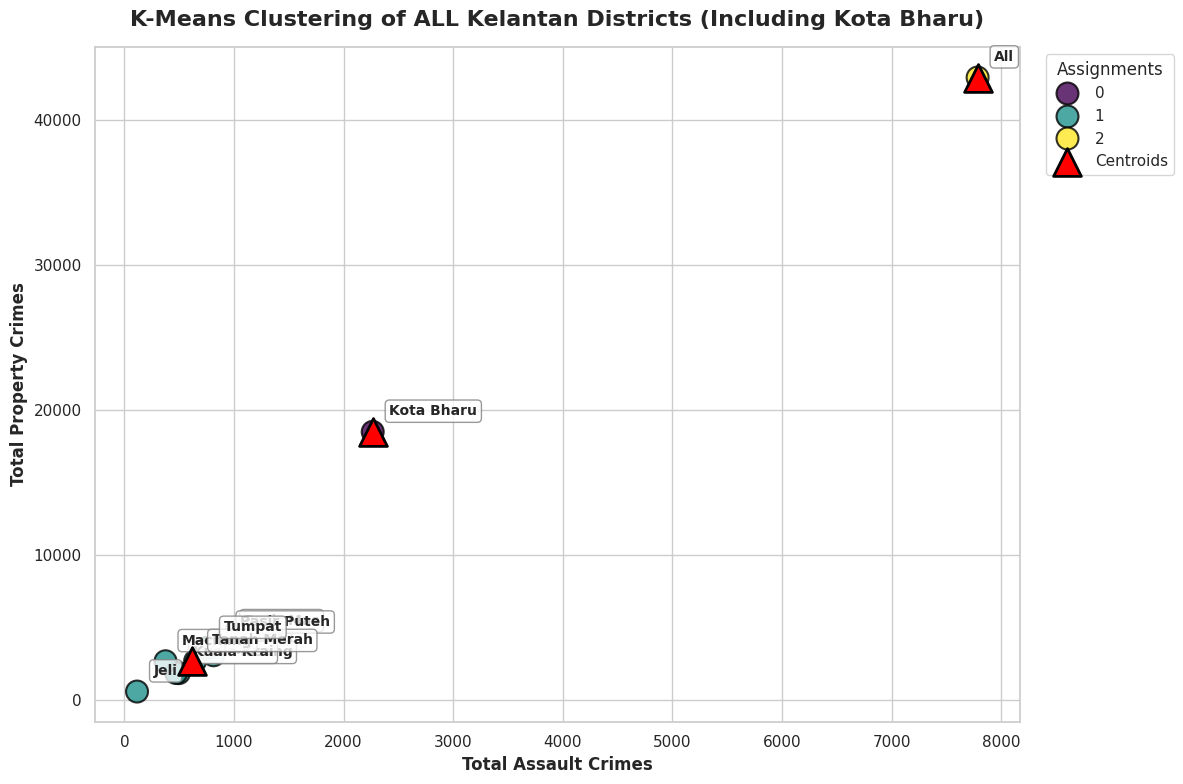

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# 1. Use the ORIGINAL clustering_df and X_scaled (which still has Kota Bharu)
feature_x = clustering_df.columns[0]
feature_y = clustering_df.columns[1]

# 2. Enhanced Scatter Plot for ALL 10 Data Points
sns.scatterplot(
    data=clustering_df,
    x=feature_x,
    y=feature_y,
    hue='Cluster',
    palette='viridis',
    s=250,
    edgecolor='black',
    linewidth=1.5,
    alpha=0.8
)

# 3. Enhanced Centroids (using the ORIGINAL kmeans_model)
centroids_original_scale = scaler.inverse_transform(kmeans_model.cluster_centers_)

plt.scatter(
    centroids_original_scale[:, 0],
    centroids_original_scale[:, 1],
    s=400,
    c='red',
    label='Centroids',
    marker='^',
    edgecolor='black',
    linewidth=2,
    zorder=10
)

# 4. Improved Text Labels for ALL 10 districts
for i, district in enumerate(clustering_df.index):
    plt.annotate(
        district,
        (clustering_df[feature_x].iloc[i], clustering_df[feature_y].iloc[i]),
        xytext=(12, 12),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

# 5. Professional Formatting
plt.title('K-Means Clustering of ALL Kelantan Districts (Including Kota Bharu)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel(f'Total {feature_x.capitalize()} Crimes', fontsize=12, fontweight='bold')
plt.ylabel(f'Total {feature_y.capitalize()} Crimes', fontsize=12, fontweight='bold')

plt.legend(title='Assignments', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=11, title_fontsize=12)

plt.tight_layout()
plt.show()

### 5. Model Evaluation
Using the Silhouette Score to evaluate the separation and cohesion of the clusters.

In [ ]:
from sklearn.metrics import silhouette_score

# Calculate Silhouette Score
sil_score = silhouette_score(X_scaled, cluster_predictions)

print(f"K-Means Silhouette Score: {sil_score:.4f}")

K-Means Silhouette Score: 0.7149


## **Hierarchical Clustering Analysis**

In [ ]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

# **Load Dataset**

In [ ]:
# Load Dataset

df = pd.read_csv('Kelantan_Crime_Statistic.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1232, 6)


,state,district,category,type,date,crimes
0,Kelantan,All,assault,all,1/1/2016,543
1,Kelantan,All,assault,all,1/1/2017,600
2,Kelantan,All,assault,all,1/1/2018,511
3,Kelantan,All,assault,all,1/1/2019,470
4,Kelantan,All,assault,all,1/1/2020,504


# **Data Inspection**

In [ ]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nUnique Districts:")
print(df['district'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1232 entries, 0 to 1231
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   state     1232 non-null   object
 1   district  1232 non-null   object
 2   category  1232 non-null   object
 3   type      1232 non-null   object
 4   date      1232 non-null   object
 5   crimes    1232 non-null   int64 
dtypes: int64(1), object(5)
memory usage: 57.9+ KB
None

Missing Values:
state       0
district    0
category    0
type        0
date        0
crimes      0
dtype: int64

Unique Districts:
['All' 'Bachok' 'Gua Musang' 'Jeli' 'Kota Bharu' 'Kuala Krai' 'Machang'
 'Pasir Mas' 'Pasir Puteh' 'Tanah Merah' 'Tumpat']


# **Data Preparation**

In [ ]:
# Remove statewide total

crime_df = df[df['district'] != 'All'].copy()

crime_df.head()

,state,district,category,type,date,crimes
112,Kelantan,Bachok,assault,all,1/1/2016,85
113,Kelantan,Bachok,assault,all,1/1/2017,56
114,Kelantan,Bachok,assault,all,1/1/2018,41
115,Kelantan,Bachok,assault,all,1/1/2019,42
116,Kelantan,Bachok,assault,all,1/1/2020,48


# **Create Feature Matrix**

In [ ]:
district_features = pd.pivot_table(
    crime_df,
    values='crimes',
    index='district',
    columns='type',
    aggfunc='sum',
    fill_value=0
)

district_features

type,all,break_in,causing_injury,murder,rape,robbery_gang_armed,robbery_gang_unarmed,robbery_solo_armed,robbery_solo_unarmed,theft_other,theft_vehicle_lorry,theft_vehicle_motorcar,theft_vehicle_motorcycle
district,,,,,,,,,,,,,
Bachok,1954,409,237,4,98,0,39,0,29,378,18,105,637
Gua Musang,1181,207,128,14,57,3,35,0,12,316,16,99,294
Jeli,355,111,24,1,26,0,4,0,3,84,4,17,81
Kota Bharu,10379,1484,369,15,218,11,303,1,216,1452,193,1533,4584
Kuala Krai,1172,209,125,3,74,0,22,0,12,346,9,94,278
Machang,1529,553,82,6,36,1,34,0,29,290,11,133,354
Pasir Mas,2498,593,233,10,101,1,68,0,56,648,22,157,609
Pasir Puteh,2434,565,210,10,101,1,88,0,42,413,21,156,827
Tanah Merah,1670,276,148,5,90,0,43,0,37,340,13,153,565


# **Data Standardization**

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(district_features)

print(X_scaled.shape)

(10, 13)


# **Correlation Analysis**

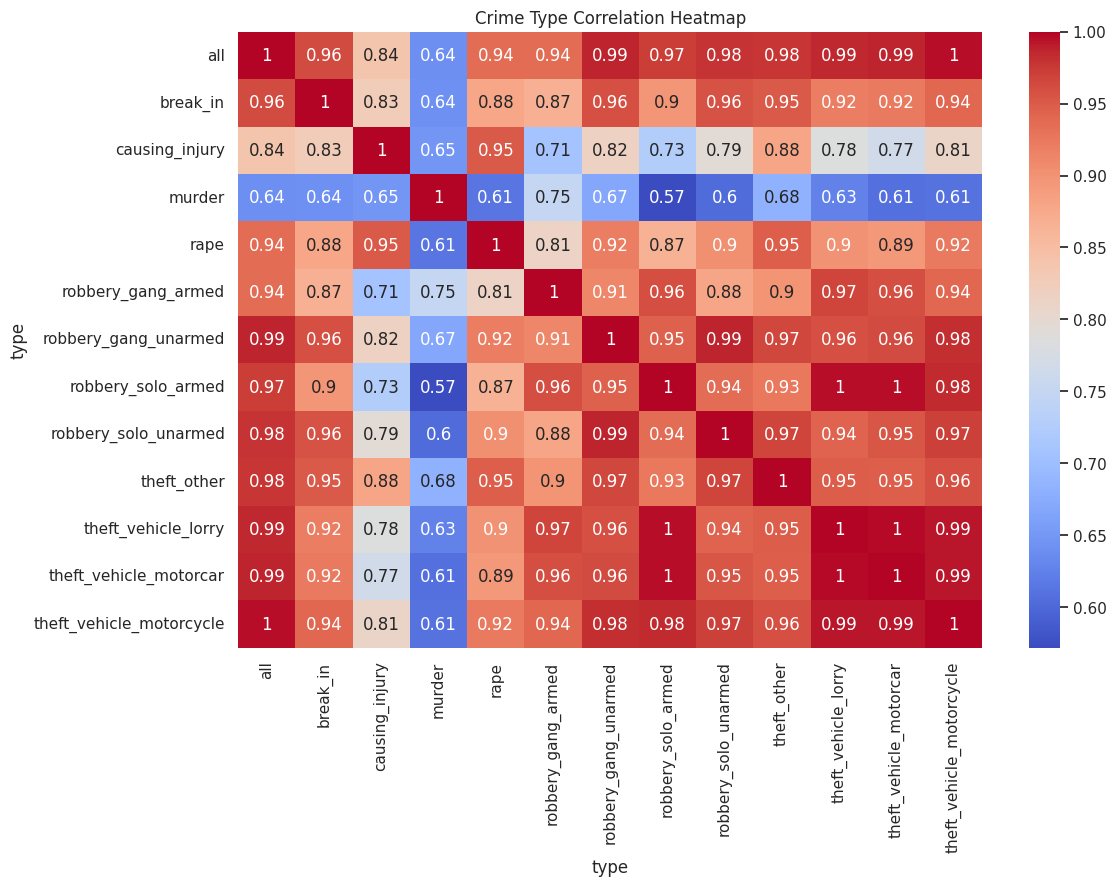

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    district_features.corr(),
    cmap='coolwarm',
    annot=True
)

plt.title('Crime Type Correlation Heatmap')

plt.show()

# **Dendrogram Visualization**

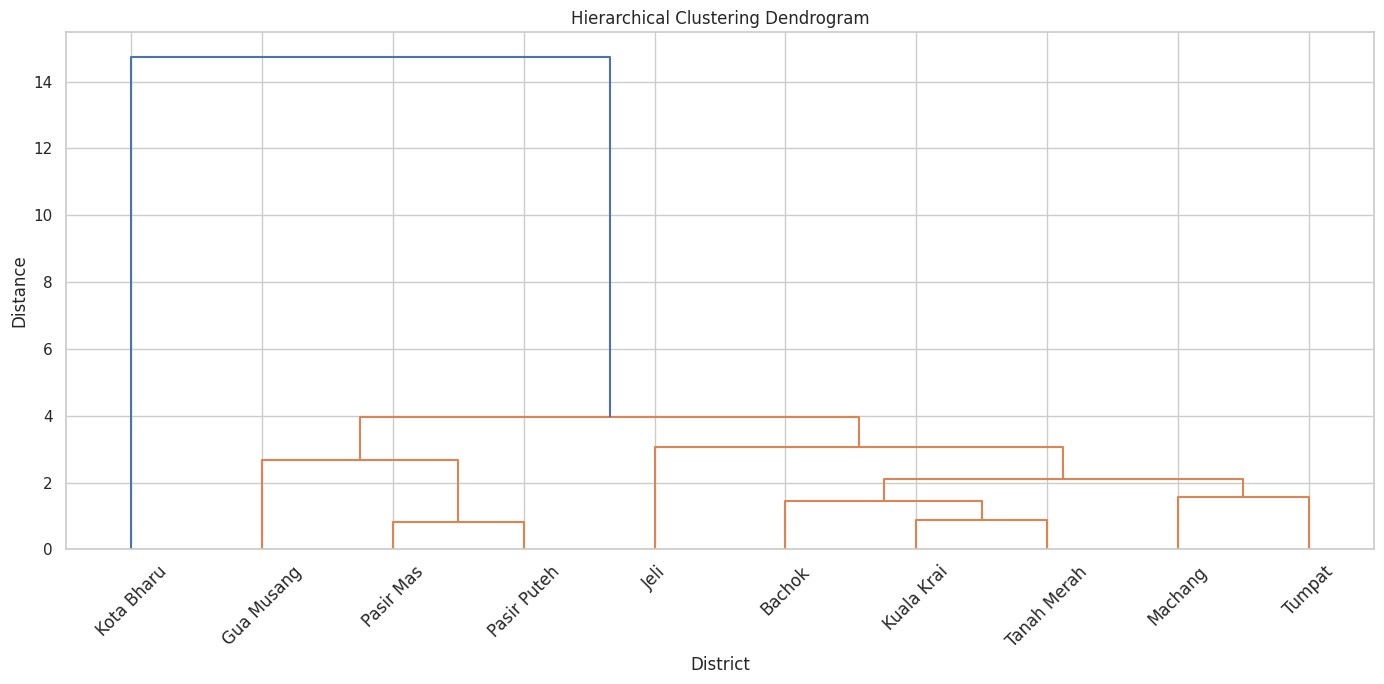

In [ ]:
linked = linkage(
    X_scaled,
    method='ward'
)

plt.figure(figsize=(14,7))

dendrogram(
    linked,
    labels=district_features.index.tolist(),
    leaf_rotation=45
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('District')
plt.ylabel('Distance')

plt.tight_layout()
plt.show()

# **Build Hierarchical Clustering Model**

In [ ]:
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

clusters = hc.fit_predict(X_scaled)

district_features['Cluster'] = clusters

district_features

type,all,break_in,causing_injury,murder,rape,robbery_gang_armed,robbery_gang_unarmed,robbery_solo_armed,robbery_solo_unarmed,theft_other,theft_vehicle_lorry,theft_vehicle_motorcar,theft_vehicle_motorcycle,Cluster
district,,,,,,,,,,,,,,
Bachok,1954,409,237,4,98,0,39,0,29,378,18,105,637,0
Gua Musang,1181,207,128,14,57,3,35,0,12,316,16,99,294,2
Jeli,355,111,24,1,26,0,4,0,3,84,4,17,81,0
Kota Bharu,10379,1484,369,15,218,11,303,1,216,1452,193,1533,4584,1
Kuala Krai,1172,209,125,3,74,0,22,0,12,346,9,94,278,0
Machang,1529,553,82,6,36,1,34,0,29,290,11,133,354,0
Pasir Mas,2498,593,233,10,101,1,68,0,56,648,22,157,609,2
Pasir Puteh,2434,565,210,10,101,1,88,0,42,413,21,156,827,2
Tanah Merah,1670,276,148,5,90,0,43,0,37,340,13,153,565,0


# **Cluster Assignment**

In [ ]:
cluster_result = district_features[['Cluster']]

cluster_result.sort_values('Cluster')

type,Cluster
district,
Bachok,0
Jeli,0
Machang,0
Kuala Krai,0
Tumpat,0
Tanah Merah,0
Kota Bharu,1
Gua Musang,2
Pasir Puteh,2


# **Cluster Distribution**

In [ ]:
district_features['Cluster'].value_counts()

,count
Cluster,
0,6
2,3
1,1


# **Silhouette Score Evaluation**

In [ ]:
silhouette = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", round(silhouette,4))

Silhouette Score: 0.226


## **PCA Visualization**

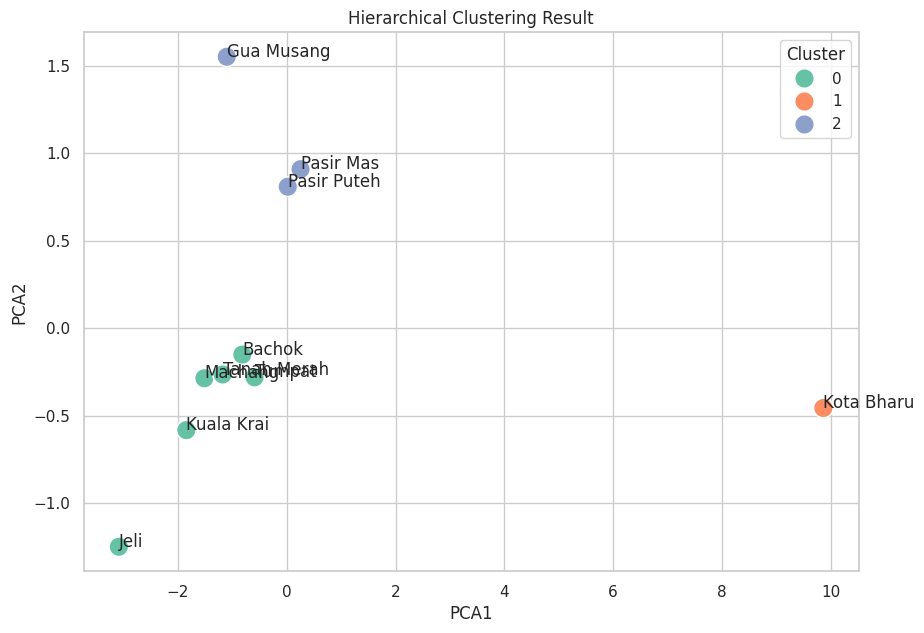

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    'PCA1': X_pca[:,0],
    'PCA2': X_pca[:,1],
    'Cluster': clusters,
    'District': district_features.index
})

plt.figure(figsize=(10,7))

sns.scatterplot(
    data=plot_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set2',
    s=200
)

for i in range(len(plot_df)):
    plt.annotate(
        plot_df['District'][i],
        (plot_df['PCA1'][i], plot_df['PCA2'][i])
    )

plt.title('Hierarchical Clustering Result')
plt.show()

## **Cluster Profiling**

In [ ]:
cluster_profile = district_features.groupby('Cluster').mean()

cluster_profile

type,all,break_in,causing_injury,murder,rape,robbery_gang_armed,robbery_gang_unarmed,robbery_solo_armed,robbery_solo_unarmed,theft_other,theft_vehicle_lorry,theft_vehicle_motorcar,theft_vehicle_motorcycle
Cluster,,,,,,,,,,,,,
0,1476.000000,342.5,124.166667,4.166667,66.333333,0.166667,39.000000,0.0,31.000000,316.5,10.833333,103.666667,437.666667
1,10379.000000,1484.0,369.000000,15.000000,218.000000,11.000000,303.000000,1.0,216.000000,1452.0,193.000000,1533.000000,4584.000000
2,2037.666667,455.0,190.333333,11.333333,86.333333,1.666667,63.666667,0.0,36.666667,459.0,19.666667,137.333333,576.666667


## **Cluster Profile Heatmap**

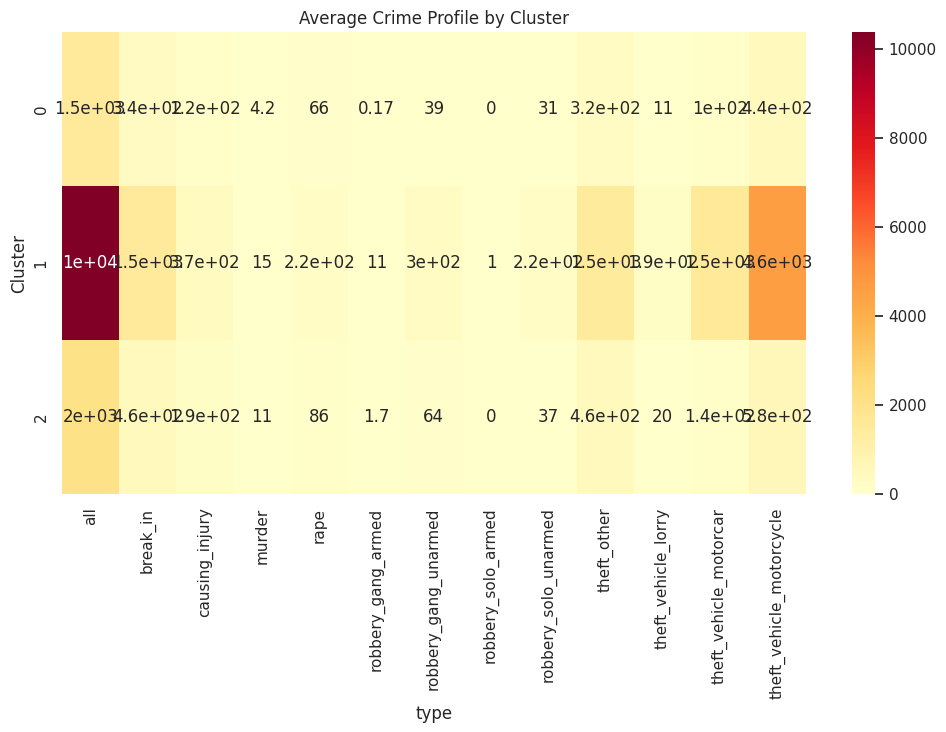

In [ ]:
plt.figure(figsize=(12,6))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap='YlOrRd'
)

plt.title('Average Crime Profile by Cluster')

plt.show()

# **DBSCAN Anomaly Detection**

In [ ]:
from sklearn.cluster import DBSCAN
import numpy as np

# **DBSCAN Parameter Tuning**

In [ ]:
from sklearn.cluster import DBSCAN
import pandas as pd

results = []

for eps in [1.0, 1.2, 1.5, 1.8, 2.0]:
    for min_samples in [2, 3, 4]:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        results.append([
            eps,
            min_samples,
            n_clusters,
            n_noise
        ])

tuning_results = pd.DataFrame(
    results,
    columns=['eps', 'min_samples', 'Clusters', 'Noise_Points']
)

print(tuning_results)

    eps  min_samples  Clusters  Noise_Points
0   1.0            2         2             6
1   1.0            3         0            10
2   1.0            4         0            10
3   1.2            2         2             5
4   1.2            3         1             7
5   1.2            4         0            10
6   1.5            2         2             4
7   1.5            3         1             6
8   1.5            4         1             6
9   1.8            2         1             2
10  1.8            3         1             2
11  1.8            4         1             2
12  2.0            2         1             2
13  2.0            3         1             2
14  2.0            4         1             2


# **Build DBSCAN Model**

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.5,
    min_samples=2
)

dbscan_labels = dbscan.fit_predict(X_scaled)

district_features['DBSCAN_Cluster'] = dbscan_labels

district_features

type,all,break_in,causing_injury,murder,rape,robbery_gang_armed,robbery_gang_unarmed,robbery_solo_armed,robbery_solo_unarmed,theft_other,theft_vehicle_lorry,theft_vehicle_motorcar,theft_vehicle_motorcycle,Cluster,DBSCAN_Cluster
district,,,,,,,,,,,,,,,
Bachok,1954,409,237,4,98,0,39,0,29,378,18,105,637,0,0
Gua Musang,1181,207,128,14,57,3,35,0,12,316,16,99,294,2,-1
Jeli,355,111,24,1,26,0,4,0,3,84,4,17,81,0,-1
Kota Bharu,10379,1484,369,15,218,11,303,1,216,1452,193,1533,4584,1,-1
Kuala Krai,1172,209,125,3,74,0,22,0,12,346,9,94,278,0,0
Machang,1529,553,82,6,36,1,34,0,29,290,11,133,354,0,-1
Pasir Mas,2498,593,233,10,101,1,68,0,56,648,22,157,609,2,1
Pasir Puteh,2434,565,210,10,101,1,88,0,42,413,21,156,827,2,1
Tanah Merah,1670,276,148,5,90,0,43,0,37,340,13,153,565,0,0


# **Cluster Distribution**

In [ ]:
import pandas as pd

pd.Series(dbscan_labels).value_counts().sort_index()

,count
-1,4
0,4
1,2


# **Identify Anomalies**

In [ ]:
anomalies = district_features[
    district_features['DBSCAN_Cluster'] == -1
]

print("Anomalous Districts:")

anomalies

Anomalous Districts:


type,all,break_in,causing_injury,murder,rape,robbery_gang_armed,robbery_gang_unarmed,robbery_solo_armed,robbery_solo_unarmed,theft_other,theft_vehicle_lorry,theft_vehicle_motorcar,theft_vehicle_motorcycle,Cluster,DBSCAN_Cluster
district,,,,,,,,,,,,,,,
Gua Musang,1181,207,128,14,57,3,35,0,12,316,16,99,294,2,-1
Jeli,355,111,24,1,26,0,4,0,3,84,4,17,81,0,-1
Kota Bharu,10379,1484,369,15,218,11,303,1,216,1452,193,1533,4584,1,-1
Machang,1529,553,82,6,36,1,34,0,29,290,11,133,354,0,-1


# **PCA Visualization**

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

dbscan_plot = pd.DataFrame({
    'PCA1': X_pca[:,0],
    'PCA2': X_pca[:,1],
    'Cluster': dbscan_labels,
    'District': district_features.index
})

# **DBSCAN Cluster Plot**

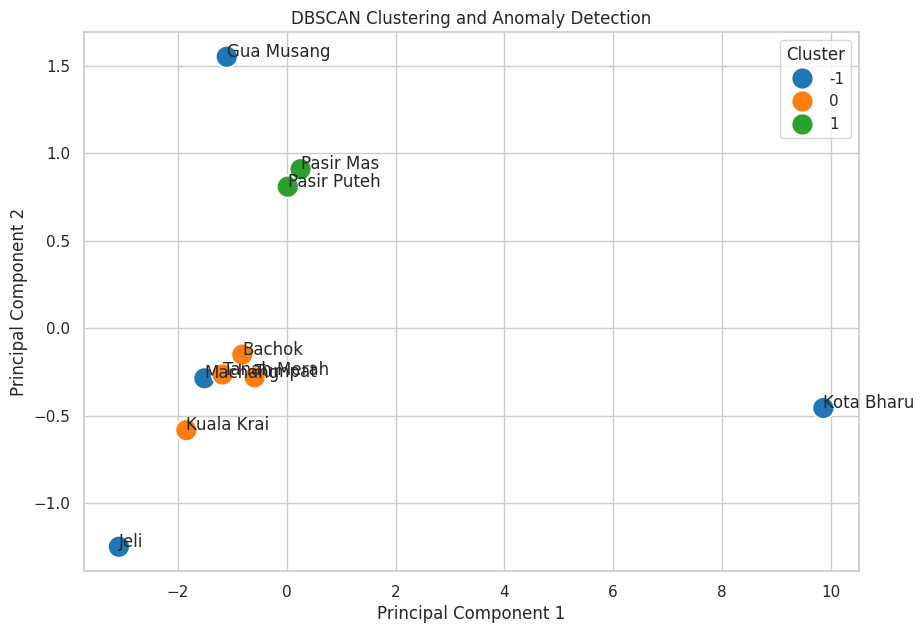

In [ ]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=dbscan_plot,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    s=250
)

for i in range(len(dbscan_plot)):
    plt.annotate(
        dbscan_plot['District'][i],
        (dbscan_plot['PCA1'][i],
         dbscan_plot['PCA2'][i])
    )

plt.title('DBSCAN Clustering and Anomaly Detection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

# **Number of Anomalies**

In [ ]:
num_anomalies = (dbscan_labels == -1).sum()

print("Number of Anomalies:", num_anomalies)

Number of Anomalies: 4
